# 8 · The Off-the-Shelf Baseline

Before training anything, measure the starting point: how well does SmolLM2-135M, which has never seen our shop,
predict the item hidden from a basket? Test: hide one item of a held-out basket, show the rest as text, score all
1,000 catalogue items as "the next item", and see where the hidden one lands.

**Metric:** MRR (mean of 1/rank) plus hits@K and median rank.

**Running on Windows/CPU, not MLX.** The course does this with MLX on a Mac GPU. Here I use PyTorch on CPU via my own
`work/mybasket/score.py` (see "What I changed" at the end). The 200-case scoring takes ~35 min on this CPU, so it was
run once as a background job (`python -m mybasket.jobs score ...`) and saved to `work/checkpoints/smollm2-base/`;
this notebook loads those scores (and recomputes them if the file is missing). Test size is the course's: 200 cases.
Only reduction here: the 40-case reshuffle "Try it" is skipped for time.

In [1]:
import os
import time
import warnings
from pathlib import Path

os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.dataset import generate_dataset
from thilimarketbasket.evaluate import candidate_token_ids, make_cases, popularity_scores
from thilimarketbasket.verbalize import verbalize_prefix

data = generate_dataset(n_baskets=100_000, seed=0)
names = [item.name for item in data.catalog]
position = {name: i for i, name in enumerate(names)}

# the same split as section 7
is_val = np.random.default_rng(0).random(len(data.baskets)) < 0.05
train = [b for b, v in zip(data.baskets, is_val) if not v]
val = [b for b, v in zip(data.baskets, is_val) if v]
print(f"{len(train):,} training baskets, {len(val):,} held out, {len(names):,} items in the catalogue")

95,002 training baskets, 4,998 held out, 1,000 items in the catalogue


## Rank and summary

Rank = 1 + number of other candidates scoring at least as high (ties count against the target). Items already in the
basket aren't candidates.

In [2]:
def my_rank_of(scores, target, exclude=()):
    """Rank of `target` (1 is best) among the items not in `exclude`. A tie counts against the target."""
    keep = np.ones(len(scores), dtype=bool)
    keep[list(exclude)] = False
    keep[target] = False                     # compare the target with the others, never with itself
    return 1 + int((scores[keep] >= scores[target]).sum())


def my_summary(ranks):
    ranks = np.asarray(ranks)
    return {"MRR": np.mean(1 / ranks), "hits@1": np.mean(ranks <= 1),
            "hits@10": np.mean(ranks <= 10), "hits@50": np.mean(ranks <= 50), "median rank": np.median(ranks)}


print(my_rank_of(np.array([0.1, 0.9, 0.5, 0.5]), 2))          # 3: one item is better and one ties
print(my_rank_of(np.array([0.1, 0.9, 0.5]), 2, exclude=[1]))   # 1: the better item is not a candidate

3
1


## The 200 test cases (held-out baskets, one item hidden)

In [3]:
cases = make_cases(val, names, n_cases=200, seed=0)

for case in cases[:3]:
    print("visible:", case["visible"])
    print("hidden: ", case["target"], "\n")

visible: ['Amulya Milk 500 ml', 'Chatpata Banana Chips Rs 5 pack', 'Garlic 1 kg', 'Golden Drop Sunflower Oil 500 ml', 'Kesari Black Pepper 200 g', 'Masala Mantra Red Chilli Powder 100 g', 'Masala Mantra Sambar Powder 100 g', 'Onion 500 g', 'Sundar Sutra Deodorant 150 ml', 'Surya Grains Wheat Flour (Atta) 1 kg', 'Swad Sagar Mustard Seeds sachet 10 g', 'Tomato 500 g']
hidden:  Nandini Pure Eggs 12 pack 

visible: ['Crunch Club Dosa Batter 500 g', 'Dhara Fresh Sunflower Oil 500 ml', 'Glow Garden Hair Oil 100 ml', 'Kaveri Valley Rice Flour 5 kg', 'Kaveri Valley Toor Dal 1 kg', 'Little Lotus Ball Pen pack of 5', 'Munch Mela Potato Chips Rs 5 pack', 'Nandini Pure Milk 500 ml', 'Rasoi Royale Turmeric Powder 100 g', 'Shubham Select Sona Masoori Rice 1 kg']
hidden:  Suryamukhi Coconut Oil 1 L 

visible: ['Chai Chaska Fruit Juice 200 ml', 'Garlic 1 kg', 'Glow Garden Razor pack of 5', 'Glow Garden Shampoo Bottle 180 ml', 'Kaveri Valley Sago (Sabudana) 250 g', 'Kids Korner Notebook pack of 5', 'Ma

## Two baselines with no model

Random order, and popularity (count of training baskets holding each item — ignores the basket entirely).

In [4]:
n = len(names)
random_mrr = np.mean(1 / np.arange(1, n + 1))
print(f"random ranking: expected MRR {random_mrr:.4f}")

pop = popularity_scores(train, names)
pop_ranks = [my_rank_of(pop, position[c["target"]], [position[v] for v in c["visible"]]) for c in cases]
print("popularity:    ", {k: round(float(v), 3) for k, v in my_summary(pop_ranks).items()})

random ranking: expected MRR 0.0075
popularity:     {'MRR': 0.052, 'hits@1': 0.005, 'hits@10': 0.12, 'hits@50': 0.39, 'median rank': 105.5}


Popularity is the bar to respect: a recommender that can't beat "suggest what everyone buys" isn't recommending.

## Scoring with a language model

Each item's score is log P(item tokens | basket so far) = sum of its tokens' log-probs. Only the *order* of the 1,000
scores matters; the chain is scores → sort → rank of the hidden item → 1/rank.

In [5]:
import torch
from mybasket.score import load, score_candidates, slow_score

torch.set_num_threads(20)
model, tokenizer = load("HuggingFaceTB/SmolLM2-135M")
print("running on: CPU,", torch.get_num_threads(), "threads")
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f} million parameters")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  56%|█████▌    | 152/272 [00:00<00:00, 1509.14it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1652.80it/s]

running on: CPU, 20 threads
135 million parameters


## Steps 1–3: text to ids

Candidates are tokenized with a leading space, because in a basket an item always follows "; ".

In [6]:
case = cases[0]
prefix = verbalize_prefix(case["visible"], seed=0)
print(repr(prefix), "\n")

candidates = candidate_token_ids(tokenizer, names)
for name in (case["target"], "Onion 1 kg"):
    ids = candidates[position[name]]
    print(f"{name}\n   {len(ids)} tokens: {[tokenizer.decode([i]) for i in ids]}")

'Basket: Surya Grains Wheat Flour (Atta) 1 kg; Garlic 1 kg; Onion 500 g; Kesari Black Pepper 200 g; Masala Mantra Red Chilli Powder 100 g; Tomato 500 g; Amulya Milk 500 ml; Golden Drop Sunflower Oil 500 ml; Masala Mantra Sambar Powder 100 g; Swad Sagar Mustard Seeds sachet 10 g; Sundar Sutra Deodorant 150 ml; Chatpata Banana Chips Rs 5 pack;' 

Nandini Pure Eggs 12 pack
   9 tokens: [' N', 'and', 'ini', ' Pure', ' Eggs', ' ', '1', '2', ' pack']
Onion 1 kg
   5 tokens: [' On', 'ion', ' ', '1', ' kg']


In [7]:
onion = candidates[position["Onion 1 kg"]]
print("with the leading space:   ", onion, [tokenizer.decode([i]) for i in onion])
without = tokenizer.encode("Onion 1 kg")
print("without the leading space:", without, [tokenizer.decode([i]) for i in without])
print(f"\nthe basket so far is {len(tokenizer.encode(prefix))} ids long, from a vocabulary of {len(tokenizer):,}")

with the leading space:    [1985, 285, 216, 33, 11134] [' On', 'ion', ' ', '1', ' kg']
without the leading space: [3280, 285, 216, 33, 11134] ['On', 'ion', ' ', '1', ' kg']

the basket so far is 140 ids long, from a vocabulary of 49,152


## Step 4: slow vs fast

Slow: run basket + item as one sequence for each item. Fast (my PyTorch port of the reference): run the basket once,
keep its key/value cache, copy it for a batch of candidates and run only the candidates' few tokens. They must agree.
(Mine computes in float32 on CPU, so they agree exactly; the course's MLX run used half precision and differed by
a few tenths.)

In [8]:
prefix_ids = tokenizer.encode(prefix)
fast = score_candidates(model, prefix_ids, candidates)

for i in (0, 400, 999):
    print(f"{names[i]:42} fast {fast[i]:8.2f}   slow {slow_score(model, prefix_ids, candidates[i]):8.2f}")

Kaveri Valley Basmati Rice 500 g           fast   -29.38   slow   -29.38


Rasoi Royale Cardamom 100 g                fast   -42.36   slow   -42.36


Kids Korner Batteries (AA) pack of 10      fast   -61.07   slow   -61.07


In [9]:
start = time.time()
for i in range(20):
    slow_score(model, prefix_ids, candidates[i])
per_slow = (time.time() - start) / 20

start = time.time()
score_candidates(model, prefix_ids, candidates)
per_fast = time.time() - start

print(f"slow way: {per_slow * 1000:.0f} ms per candidate, about {per_slow * 1000:.0f} s for all 1,000 items")
print(f"cached:   {per_fast:.1f} s for all 1,000 items")

slow way: 429 ms per candidate, about 429 s for all 1,000 items
cached:   25.3 s for all 1,000 items


## One case, start to finish

In [10]:
print("Basket so far, written to the model as text (the order is shuffled):")
for item in case["visible"]:
    print("  -", item)
print(f"\nHidden item, which the model has to find: {case['target']}")

Basket so far, written to the model as text (the order is shuffled):
  - Amulya Milk 500 ml
  - Chatpata Banana Chips Rs 5 pack
  - Garlic 1 kg
  - Golden Drop Sunflower Oil 500 ml
  - Kesari Black Pepper 200 g
  - Masala Mantra Red Chilli Powder 100 g
  - Masala Mantra Sambar Powder 100 g
  - Onion 500 g
  - Sundar Sutra Deodorant 150 ml
  - Surya Grains Wheat Flour (Atta) 1 kg
  - Swad Sagar Mustard Seeds sachet 10 g
  - Tomato 500 g

Hidden item, which the model has to find: Nandini Pure Eggs 12 pack


In [11]:
exclude = [position[v] for v in case["visible"]]
allowed = [i for i in np.argsort(-fast) if i not in set(exclude)]
rank = my_rank_of(fast, position[case["target"]], exclude)

print("The model's ten favourite next items:\n")
print(f"  {'rank':>4}  {'item':40} {'score':>7}")
for place, i in enumerate(allowed[:10], 1):
    print(f"  {place:>4}  {names[i]:40} {fast[i]:7.2f}")

print(f"\nThe hidden item, {case['target']}, is at rank {rank}.")
print(f"Its reciprocal rank for this case is 1 / {rank} = {1 / rank:.4f}")

The model's ten favourite next items:

  rank  item                                       score
     1  Potato 500 g                               -8.39
     2  Potato 1 kg                                -8.52
     3  Ginger 500 g                               -9.22
     4  Onion 1 kg                                 -9.77
     5  Cabbage 1 kg                               -9.78
     6  Lemon 500 g                               -10.30
     7  Cabbage 500 g                             -10.31
     8  Cauliflower 1 kg                          -10.35
     9  Carrot 1 kg                               -10.41
    10  Spinach 1 kg                              -10.53

The hidden item, Nandini Pure Eggs 12 pack, is at rank 699.
Its reciprocal rank for this case is 1 / 699 = 0.0014


## The baseline: all 200 cases

Loaded from the background job's output (same code: `verbalize_prefix(..., seed=k)` then `score_candidates`).

In [12]:
BASE = Path("checkpoints") / "smollm2-base"
if (BASE / "scores-200.npy").exists():
    model_scores = list(np.load(BASE / "scores-200.npy"))
    print(f"loaded {len(model_scores)} cases scored by the background job "
          f"({__import__('json').loads((BASE / 'scores-200.json').read_text())['minutes_last_run']:.0f} minutes on this CPU)")
else:
    start = time.time()
    model_scores = []
    for k, case in enumerate(cases):
        prefix_ids = tokenizer.encode(verbalize_prefix(case["visible"], seed=k))
        model_scores.append(score_candidates(model, prefix_ids, candidates))
    print(f"{len(cases)} cases in {(time.time() - start) / 60:.1f} minutes")
print("case 0 matches the live scores above:", np.allclose(model_scores[0], fast))

def ranks_for(score_list):
    return [my_rank_of(s, position[c["target"]], [position[v] for v in c["visible"]]) for s, c in zip(score_list, cases)]

model_ranks = ranks_for(model_scores)
pd.DataFrame({"random": {"MRR": random_mrr}, "popularity": my_summary(pop_ranks),
              "off-the-shelf model": my_summary(model_ranks)}).T.round(3)

loaded 200 cases scored by the background job (46 minutes on this CPU)
case 0 matches the live scores above: True


,MRR,hits@1,hits@10,hits@50,median rank
random,0.007,NaN,NaN,NaN,NaN
popularity,0.052,0.005,0.12,0.390,105.5
off-the-shelf model,0.021,0.000,0.05,0.195,342.0


## How much can we trust it? Bootstrap 95% ranges

Resample the 200 reciprocal ranks with replacement 2,000 times and keep the middle 95% of the means.

In [13]:
def mrr_interval(ranks, draws=2000, seed=0):
    rng = np.random.default_rng(seed)
    reciprocal = 1 / np.asarray(ranks)
    means = [rng.choice(reciprocal, size=len(reciprocal)).mean() for _ in range(draws)]
    return np.percentile(means, [2.5, 97.5])

for label, ranks in (("popularity", pop_ranks), ("off-the-shelf model", model_ranks)):
    low, high = mrr_interval(ranks)
    print(f"{label:20} MRR {np.mean(1 / np.asarray(ranks)):.3f}   (95% range {low:.3f} to {high:.3f})")

popularity           MRR 0.052   (95% range 0.037 to 0.069)
off-the-shelf model  MRR 0.021   (95% range 0.013 to 0.030)


## Is the model reading the basket at all?

Score all items after just "Basket:" (no items) — one fixed ranking for every case = the model's taste in names.

In [14]:
with_basket = verbalize_prefix(cases[0]["visible"], seed=0)
header = tokenizer.encode("Basket:")
print("with a basket:", repr(with_basket[:60]) + " ...", f"({len(tokenizer.encode(with_basket))} ids)")
print("no basket:    ", repr("Basket:"), f"({len(header)} ids)", [tokenizer.decode([i]) for i in header])

with a basket: 'Basket: Surya Grains Wheat Flour (Atta) 1 kg; Garlic 1 kg; O' ... (140 ids)
no basket:     'Basket:' (3 ids) ['B', 'asket', ':']


In [15]:
blank = score_candidates(model, tokenizer.encode("Basket:"), candidates)
blank_ranks = ranks_for([blank] * len(cases))
print("ranking by the model's no-basket scores:", {k: round(float(v), 3) for k, v in my_summary(blank_ranks).items()})
print("ranking by its scores given the basket: ", {k: round(float(v), 3) for k, v in my_summary(model_ranks).items()})

ranking by the model's no-basket scores: {'MRR': 0.029, 'hits@1': 0.01, 'hits@10': 0.06, 'hits@50': 0.18, 'median rank': 344.0}
ranking by its scores given the basket:  {'MRR': 0.021, 'hits@1': 0.0, 'hits@10': 0.05, 'hits@50': 0.195, 'median rank': 342.0}


Is it length? Longer names collect more negative log-probs:

In [16]:
lengths = np.array([len(c) for c in candidates])
print(f"correlation between a name's token count and its score: {np.corrcoef(lengths, blank)[0, 1]:.2f}")

per_token = [s / lengths for s in model_scores]
print("\nscore divided by token count:", {k: round(float(v), 3) for k, v in my_summary(ranks_for(per_token)).items()})

correlation between a name's token count and its score: -0.60

score divided by token count: {'MRR': 0.014, 'hits@1': 0.0, 'hits@10': 0.03, 'hits@50': 0.12, 'median rank': 382.0}


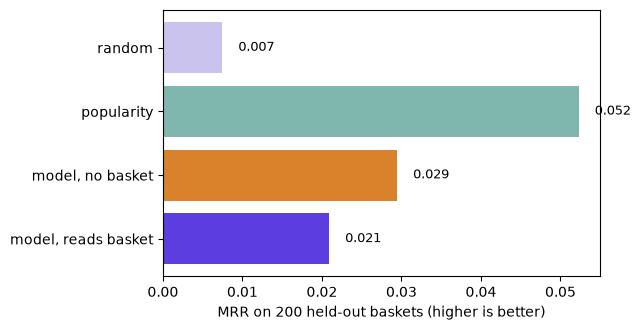

In [17]:
rows = {"random": random_mrr, "popularity": np.mean(1 / np.asarray(pop_ranks)),
        "model, no basket": np.mean(1 / np.asarray(blank_ranks)),
        "model, reads basket": np.mean(1 / np.asarray(model_ranks))}
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.barh(list(rows), list(rows.values()), color=["#c9c3ee", "#7fb7ae", "#d9822b", "#5b3de0"])
ax.invert_yaxis()
ax.set_xlabel("MRR on 200 held-out baskets (higher is better)")
for i, v in enumerate(rows.values()):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## Try it: does the shuffle matter? — **skipped for time**

The course re-scores the first 40 cases with a different item order (seed 1000 + k) to see how much the order moves
each rank (course: the MRR barely moved, 0.009 → 0.010, but 38 of 40 ranks changed). On this CPU that is 40 more
cases × ~13 s ≈ 9 minutes, so I skipped it to save time. The code to run it later:

```python
again = [score_candidates(model, tokenizer.encode(verbalize_prefix(c["visible"], seed=1000 + k)), candidates)
         for k, c in enumerate(cases[:40])]
```

## What I changed from the course (no Mac)

- **Scoring:** the course's `score_candidates` needs MLX. Its PyTorch appendix re-reads the whole basket for every
  batch of candidates — far too slow on a CPU. I wrote `work/mybasket/score.py`: same idea as the MLX reference (run the
  basket once, copy its key/value cache with `DynamicCache.batch_repeat_interleave`, run only the candidate tokens),
  in float32. Small fixes vs the appendix: `dtype=` instead of the deprecated `torch_dtype=`; batches of 100 instead of
  250 and `logit − logsumexp` instead of a full `log_softmax` (the first try at 250 ran out of memory in Docker).
- **Check:** fast and slow scores agree exactly (cell above).
- **Same test size as the course:** 200 cases × 1,000 candidates, same seeds.
- **Reduction (to save time):** the "Try it" reshuffle of 40 cases was skipped. Nothing else in this section is
  reduced. (Sections 9 and 11 compare models on the first 100 of these 200 cases — see those notebooks.)
- Everything else (cases, popularity, ranks, bootstrap) uses the package / course code unchanged.

## Test yourself

**1. Why does MRR reward rank 1 so much more than rank 10?**
Each case scores 1/rank, so rank 1 gives 1.0, rank 2 gives 0.5 and rank 10 only 0.1. That matches a recommender's
job: only the top few suggestions get seen, so being first matters far more than being 10th or 100th.

**2. Why must candidate names be scored with a leading space?**
In the training text an item always follows "; ", so the model sees " Onion" (with the space), which is a different
token from "Onion". Scoring without the space would ask about a sequence that never appears in a basket.

**3. What does it mean that the model does about as well with no basket as with one?**
It's ranking mostly by how natural each name looks as text, not by what's in the basket. An off-the-shelf model has
never seen our shop, so it isn't using the basket to predict what goes with it — and it loses to plain popularity.

## My notes

An untrained model that never saw our shop scores MRR 0.021, well below just suggesting best sellers (0.052), and it does no better when shown the basket. Surprising: the obvious one-candidate-at-a-time scoring would take 7 minutes per basket on my CPU; reusing the basket's cache brings it to about 25 seconds.